# Necessary imports

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from prettytable import PrettyTable
from statistics import mean
from math import sqrt
from numpy import linalg as lin
import time
import psutil
import os
import tracemalloc
from tabulate import tabulate
from collections import deque

MAX_ITER = 10000

# Target function examples

In [2]:
names = ['x^2 + 2xy + 3y^2',
         '4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 45y^2 - 8x + 62y + 11',
         '15x^2 + 3y^2 - 7x + 11y - 8']

functions = [lambda pars : pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
             lambda pars : 4 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
             lambda pars : 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 45 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
             lambda pars : 15 * pars[0] ** 2 + 3 * pars[1] ** 2 - 7 * pars[0] + 11 * pars[1] - 8]


derivates = [lambda pars : np.array([2*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
             lambda pars : np.array([8*(pars[0] - 1) + 4*pars[1], 6*(pars[1] - 3) + 4 * pars[0]]),
             lambda pars : np.array([70 * pars[0] + 71 * pars[1] - 8, 90 * pars[1] + 71 * pars[0] + 62]),
             lambda pars : np.array([30 * pars[0] - 7, 6 * pars[1] + 11])]

hessian = [lambda pars : np.array([[2,2],[2,6]]),
           lambda pars : np.array([[8,4],[4,6]]),
           lambda pars : np.array([[70,71],[71,90]]),
           lambda pars : np.array([[30,0],[0,6]])]

minimums = [np.array([0, 0]), np.array([-0.75, 3.5]), np.array([4.06, -3.89]), np.array([0.233, -1.83])]

names_with_scaling = ['1000000x^2 + 2xy + 3y^2',
         '1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11',
         '15x^2 + 1000000y^2 - 7x + y - 8']

functions_with_scaling = [lambda pars : 1000000*pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
             lambda pars : 1000000 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
             lambda pars : 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 1000000 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
             lambda pars : 15 * pars[0] ** 2 + 1000000 * pars[1] ** 2 - 7 * pars[0] + pars[1] - 8]

derivates_with_scaling = [lambda pars : np.array([2000000*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
             lambda pars : np.array([2000000*(pars[0] - 1) + 4*pars[1], 6*(pars[1] - 3) + 4 * pars[0]]),
             lambda pars : np.array([70 * pars[0] + 71 * pars[1] - 8, 2000000 * pars[1] + 71 * pars[0] + 62]),
             lambda pars : np.array([30 * pars[0] - 7, 2000000 * pars[1] + 1])]

hessian_with_scaling = [lambda pars : np.array([[2000000,2],[2,6]]),
                        lambda pars : np.array([[2000000,4],[4,6]]),
                        lambda pars : np.array([[70,71],[71,2000000]]),
                        lambda pars : np.array([[30,0],[0,2000000]])]

mimimums_with_scaling = [np.array([0,0]), np.array([1, 2.56]), np.array([0.12, 0]), np.array([0.22, 0])]

name_ros = ['100(y - x^2)^2 + (1 - x)^2']
function_ros = [lambda pars : 100 * (pars[1] - pars[0] ** 2) ** 2 + (1 - pars[0]) ** 2]
derivate_ros = [lambda pars : np.array([400 * pars[0]**3 + (2 - 400 * pars[1]) * pars[0] - 2,
                                     200 * (pars[1] - pars[0]**2)])]

hessian_ros = [lambda pars : np.array([[1200*pars[0]**2 - 400*pars[1]+2, -400*pars[0]], [-400*pars[0], 200]])]

minimum_ros = [np.array([1, 1])]

default_points = [np.array([-10,10]),np.array([-10,10]),np.array([-10,10]),np.array([-10,10])]

near_points = [np.array([-1,1]), np.array([-1.0,4.0]), np.array([3.0,-4.0]), np.array([2.0,-3.0])]

far_points = [np.array([-5.0, 5.0]), np.array([-10.0,10.0]), np.array([7.0,-9.0]), np.array([-5.0,5.0])]

# Target Functions for regression

In [3]:
t = np.linspace(0, 5, 100)

names_r = ['x^2 + 2xy + 3y^2',
         '4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 45y^2 - 8x + 62y + 11',
         '15x^2 + 3y^2 - 7x + 11y - 8']

functions_r = np.array([
    lambda pars : t * pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
    lambda pars : t * 4 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
    lambda pars : t * 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 45 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
    lambda pars : t * 15 * pars[0] ** 2 + 3 * pars[1] ** 2 - 7 * pars[0] + 11 * pars[1] - 8,
])

derivates_r = np.array([
    lambda pars : np.array([t * 2 *pars[0] + 2*pars[1], 2*pars[0] + t*6*pars[1]]).T,
    lambda pars : np.array([t * 8*(pars[0] - 1) + 4*pars[1], t*6*(pars[1] - 3) + 4 * pars[0]]).T,
    lambda pars : np.array([t * 70 * pars[0] + 71 * pars[1] - 8, t * 90 * pars[1] + 71 * pars[0] + 62]).T,
    lambda pars : np.array([t * 30 * pars[0] - 7, t * 6 * pars[1] + 11]).T,
])

minimums_r = [np.array([0., 0.]),
                    np.array([-0.75, 3.5]),
                    np.array([4.06, -3.89]), 
                    np.array([0.233, -1.83])]

default_points_r = [np.array([-10.,1.]),
                    np.array([-1.,1.]),
                    np.array([-1.,1.]),
                    np.array([-1.,1.])]


names_with_scaling_r = ['1000000x^2 + 2xy + 3y^2',
         '1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11',
         '15x^2 + 1000000y^2 - 7x + y - 8']

functions_with_scaling_r = [lambda pars : t * 1000000*pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
             lambda pars : t * 1000000 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
             lambda pars : t * 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 1000000 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
             lambda pars : t * 15 * pars[0] ** 2 + 1000000 * pars[1] ** 2 - 7 * pars[0] + pars[1] - 8]

derivates_with_scaling_r = [lambda pars : np.array([t * 2000000*pars[0] + 2*pars[1], t * 2*pars[0] + 6*pars[1]]).T,
             lambda pars : np.array([t * 2000000*(pars[0] - 1) + 4*pars[1], t * 6*(pars[1] - 3) + 4 * pars[0]]).T,
             lambda pars : np.array([t * 70 * pars[0] + 71 * pars[1] - 8, t * 2000000 * pars[1] + 71 * pars[0] + 62]).T,
             lambda pars : np.array([t * 30 * pars[0] - 7, t * 2000000 * pars[1] + 1]).T]

minimums_with_scaling_r = [np.array([0,0]), np.array([1, 2.56]), np.array([0.12, 0]), np.array([0.22, 0])]

name_ros_r = ['100(y - x^2)^2 + (1 - x)^2']
function_ros_r = [lambda pars : t * 100 * (pars[1] - pars[0] ** 2) ** 2 + (1 - pars[0]) ** 2]
derivate_ros_r = [lambda pars : np.array([t * 400 * pars[0]**3 + (2 - 400 * pars[1]) * pars[0] - 2,
                                     t * 200 * (pars[1] - pars[0]**2)]).T]

minimum_ros_r = [np.array([1, 1])]


# Testing Regresssion Methods

# Gauss-Newton implementation

In [4]:
def gauss_newton(f, J, x0, y, hess=None, tol=1e-6):
    x = x0.copy()
    iter_num = 0
    for i in range(MAX_ITER):
        # print(x)
        r = f(x) - y
        J_r = J(x).T @ r
        J_J = J(x).T @ J(x)
        try:
          dx = lin.solve(J_J, -J_r)
        except lin.LinAlgError:
          print('Singular Matrix error, aborting')
          return x, i, False
        else:
          x += dx
          if lin.norm(dx) < tol:
              iter_num = i
              break
    return x, iter_num, iter_num < MAX_ITER

# Powell Dog Leg Method

In [5]:
def dogleg(Hk, gk, Bk, trust_radius):

    # Compute the Newton point.
    pB = -np.dot(Hk, gk)
    norm_pB = sqrt(np.dot(pB, pB))
    # norm_pB = sqrt(np.dot(pB.T, pB))

    # Test if the full step is within the trust region.
    if norm_pB <= trust_radius:
        return pB
    
    # Compute the Cauchy point.
    pU = - (np.dot(gk, gk) / np.dot(gk, np.dot(Bk, gk))) * gk
    dot_pU = np.dot(pU, pU)
    norm_pU = sqrt(dot_pU)

    # If the Cauchy point is outside the trust region,
    if norm_pU >= trust_radius:
        return trust_radius * pU / norm_pU

    pB_pU = pB - pU
    dot_pB_pU = np.dot(pB_pU, pB_pU)
    dot_pU_pB_pU = np.dot(pU, pB_pU)
    fact = dot_pU_pB_pU**2 - dot_pB_pU * (dot_pU - trust_radius**2)
    tau = (-dot_pU_pB_pU + sqrt(fact)) / dot_pB_pU
    
    # Decide on which part of the trajectory to take.
    return pU + tau * pB_pU

def powell_dogleg(func, jac, x0, y=None, hess=None, eta=0.15, epsilon=1e-6):
    xk = x0
    trust_radius = 1.0
    max_trust_radius=100.0
    k = 0
    while k <= MAX_ITER:

        gk = jac(xk)
        Bk = hess(xk)
        Bk = Bk.T
        Hk = np.linalg.inv(Bk)
        
        pk = dogleg(Hk, gk, Bk, trust_radius)
       
        # Actual reduction.
        act_red = func(xk) - func(xk + pk)
        
        # Predicted reduction.
        pred_red = -(np.dot(gk, pk) + 0.5 * np.dot(pk, np.dot(Bk, pk)))
        
        # Rho.
        rhok = act_red / (pred_red + 1e-30)
            
        # Calculate the Euclidean norm of pk.
        norm_pk = sqrt(np.dot(pk, pk))
        
        # Rho is close to zero or negative, therefore the trust region is shrunk.
        if rhok.all() < 0.25:
            trust_radius = 0.25 * norm_pk
        elif rhok.all() > 0.75 and norm_pk == trust_radius: 
        # Rho is close to one and pk has reached the boundary of the trust region, therefore the trust region is expanded.
            trust_radius = min(2.0*trust_radius, max_trust_radius)
        
        # Choose the position for the next iteration.
        if rhok.all() > eta:
            xk = xk + pk
            
        # Check if the gradient is small enough to stop
        if lin.norm(gk) < epsilon:
            break
        
        # Check if we have looked at enough iterations
        k = k + 1
    
    return xk, k, xk

## Non linear regression solution

found [2.01651772 0.49875134] actual [2.  0.5]


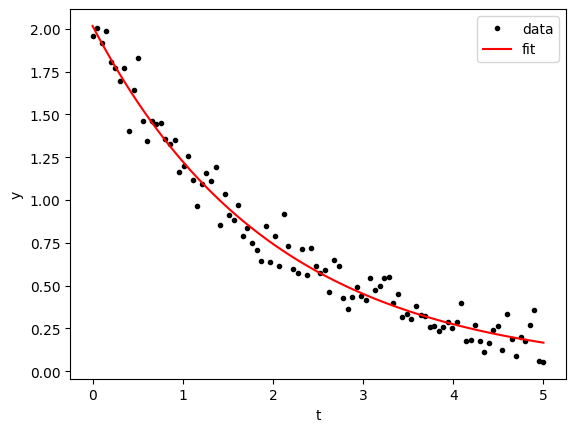

In [6]:
#Non Polynomial functions

def function_nonlinear(x):
  return x[0] * np.exp(-x[1] * t)

derivate_nonlinear = lambda x : np.array([
        np.exp(-x[1] * t),
        -t * x[0] * np.exp(-x[1] * t)
    ]).T
hessian_nonlinear = lambda x : np.array([[0,-t * np.exp(-x[1]*t)],[-t * np.exp(-x[1]*t), x[0]*np.exp(-x[1]*t) * t**2]])

minimum_nonlinear = np.array([2.0, 0.5])


default_point_nonlinear = np.array([1.0, 1.0])

def funcion(x):
  return x[0] * np.exp(-x[1] * t)


y = funcion(minimum_nonlinear)
y += 0.1 * np.random.randn(*y.shape)
result = gauss_newton(function_nonlinear, derivate_nonlinear, default_point_nonlinear, y)
# Plot the results
print("found", result[0], 'actual', minimum_nonlinear)
plt.plot(t, y, 'k.', label='data')
plt.plot(t, function_nonlinear(result[0]), 'r-', label='fit')
plt.legend()
plt.xlabel('t')
plt.ylabel('y')
plt.show()

## Test efficiency

In [9]:
def regression_tester(ns, fs, dxs, xs, mins):
  columns = 8
  table = np.array(['Function', 'Method', 'found point', 'actual', 'Converged', 'Iterations taken', 'Time taken', 'Used Memory'])
  for method in [gauss_newton]:
    for name, function, derivate, point, minimum in zip(ns, fs, dxs, xs, mins):
      start_time = time.time()
      process = psutil.Process(os.getpid())
      tracemalloc.start()
      y = function(minimum)
      y += 0.1 * np.random.randn(*y.shape)
      result = method(function, derivate, point, y)
      total_mem = tracemalloc.get_traced_memory()[1]
      tracemalloc.stop()
      total_time = round(time.time() - start_time, 4)
      table = np.append(table, np.array([name,
                                            method.__name__,                                        
                                            result[0], minimum, result[2],
                                            result[1], str(total_time) + ' s', str(total_mem) + ' bytes'], dtype=object))
  
  table = np.reshape(table, ((int)(table.size / columns), columns))
  print(tabulate(table, headers='firstrow', tablefmt='fancy_grid'))

def powell_tester(names, functions, derivates, points, minimums, hessians):
  table = np.array(['Function', 'Method', 'found point', 'actual', 'Converged', 'Iterations taken', 'Time taken', 'Used Memory'])
  columns = 8
  for method in [powell_dogleg]:
    for name, function, derivate, point, minimum, hessian in zip(names, functions, derivates, points, minimums, hessians):
      start_time = time.time()
      process = psutil.Process(os.getpid())
      tracemalloc.start()
      result = method(function, derivate, point, hess=hessian)
      total_mem = tracemalloc.get_traced_memory()[1]
      tracemalloc.stop()
      total_time = round(time.time() - start_time, 4)
      table = np.append(table, np.array([name,
                                            method.__name__,                                        
                                            result[2], minimum, result[1] <= MAX_ITER,
                                            result[1], str(total_time) + ' s', str(total_mem) + ' bytes'], dtype=object))
  
  table = np.reshape(table, ((int)(table.size / columns), columns))
  print(tabulate(table, headers='firstrow', tablefmt='fancy_grid'))

In [10]:
print("==========================Normal Testing========================")
regression_tester(names_r, functions_r, derivates_r, default_points_r, minimums_r)
powell_tester(names, functions, derivates, default_points, minimums, hessian)
print()
print()

print("==========================Scaled Testing========================")
regression_tester(names_with_scaling_r, functions_with_scaling_r, derivates_with_scaling_r, default_points_r, minimums_with_scaling_r)
powell_tester(names_with_scaling, functions_with_scaling, derivates_with_scaling, default_points, mimimums_with_scaling, hessian_with_scaling)
print()
print()

print("==========================Rosembrock Test========================")
regression_tester(name_ros_r, function_ros_r, derivate_ros_r, default_points_r, minimum_ros_r)
powell_tester(name_ros, function_ros, derivate_ros, default_points, minimum_ros, hessian_ros)
print()
print()

==========================Normal Testing========================
Singular Matrix error, aborting
╒══════════════════════════════════════╤══════════════╤═══════════════════════════════════╤═════════════════╤═════════════╤════════════════════╤══════════════╤═══════════════╕
│ Function                             │ Method       │ found point                       │ actual          │ Converged   │   Iterations taken │ Time taken   │ Used Memory   │
╞══════════════════════════════════════╪══════════════╪═══════════════════════════════════╪═════════════════╪═════════════╪════════════════════╪══════════════╪═══════════════╡
│ x^2 + 2xy + 3y^2                     │ gauss_newton │ [-0.46687544  0.28428924]         │ [0. 0.]         │ True        │                  0 │ 6.6048 s     │ 97101 bytes   │
├──────────────────────────────────────┼──────────────┼───────────────────────────────────┼─────────────────┼─────────────┼────────────────────┼──────────────┼───────────────┤
│ 4(x - 1)^2 + 3(y - 3)

<ipython-input-3-4e302f3ca9a1>:39: RuntimeWarning: invalid value encountered in multiply
  lambda pars : t * 1000000 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
<ipython-input-3-4e302f3ca9a1>:44: RuntimeWarning: invalid value encountered in multiply
  lambda pars : np.array([t * 2000000*(pars[0] - 1) + 4*pars[1], t * 6*(pars[1] - 3) + 4 * pars[0]]).T,
<ipython-input-4-df0aad3e6ae5>:7: RuntimeWarning: overflow encountered in matmul
  J_r = J(x).T @ r
<ipython-input-3-4e302f3ca9a1>:45: RuntimeWarning: invalid value encountered in multiply
  lambda pars : np.array([t * 70 * pars[0] + 71 * pars[1] - 8, t * 2000000 * pars[1] + 71 * pars[0] + 62]).T,


Singular Matrix error, aborting
╒═══════════════════════════════════════════╤══════════════╤═══════════════════════════════════╤═════════════╤═════════════╤════════════════════╤══════════════╤═══════════════╕
│ Function                                  │ Method       │ found point                       │ actual      │ Converged   │   Iterations taken │ Time taken   │ Used Memory   │
╞═══════════════════════════════════════════╪══════════════╪═══════════════════════════════════╪═════════════╪═════════════╪════════════════════╪══════════════╪═══════════════╡
│ 1000000x^2 + 2xy + 3y^2                   │ gauss_newton │ [-2.97931662e-05 -1.20603801e-02] │ [0 0]       │ True        │                  0 │ 3.373 s      │ 72313 bytes   │
├───────────────────────────────────────────┼──────────────┼───────────────────────────────────┼─────────────┼─────────────┼────────────────────┼──────────────┼───────────────┤
│ 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3   │ gauss_newton │ [nan nan]             

# Adam GD from last lab

In [14]:
class GD:  
  #static members
  MAX_ITERATIONS = 10000

  #setters
  def set_initial_points(self, points):
    if (points is None):
      return
    if (points.size != self.n):
      return
    self.initial_points = points[:]

  def set_epsilon(self, epsilon):
    self.epsilon = epsilon

  def set_step(self, step):
    self.step = step

  def set_points(self, points):
    self.points = points
  
  def init_adam(self):
    self.step = 0.1
    self.beta1 = 0.9
    self.beta2 = 0.999
    self.grad_sum = 0
    self.sq_grad_sum = 0

  #Constructor
  def __init__(self, n = 2, initial_points=None, epsilon=0.0000001, step = 0.01):
    self.n = n
    if (initial_points is None):
      self.initial_points = np.zeros(n)
    else:
      self.initial_points = initial_points
    self.epsilon = epsilon
    self.step = step

    self.step = 0.1
    self.beta1 = 0.9
    self.beta2 = 0.999
    self.grad_sum = 0
    self.sq_grad_sum = 0


  def adam(self, grad):
    self.grad_sum = self.grad_sum * self.beta1 + grad * (1 - self.beta1)
    self.sq_grad_sum = self.sq_grad_sum * self.beta2 + ((grad ** 2.0) * (1 - self.beta2))
    vector_sqrt = np.vectorize(sqrt)
    return -1 * (self.step * self.grad_sum) / (vector_sqrt(self.sq_grad_sum + self.epsilon))



  def gradient_descent(self, function, derivate, initial_points=None, hess=None, n = 2):
    self.init_adam()
    iteration = 0
    last_points = ini_points = initial_points.copy()
    points = last_points[:]
    ans = np.array(points[:])
    dif = np.zeros(points.size);
    while iteration <= self.MAX_ITERATIONS:
      difArray = derivate(points)
      dif = self.adam(difArray)
      
      points = last_points[:] + dif
      ans = np.append(ans, points[:])

      result1 = function(last_points)
      result2 = function(points)
      if (lin.norm(difArray) < self.epsilon) or (lin.norm(points - last_points) < self.epsilon) or (abs(result2 - result1) < self.epsilon):
        break
      iteration += 1
      last_points = points[:]
    return ans, iteration, last_points





  # ======================Testing and Drawing======================= #

  def plot_graph(self, function, derivate, initial_points=default_points, sizex=10, sizey=10):
    x = np.linspace(-sizex, sizex, 100)
    y = np.linspace(-sizey, sizey, 100)
    X, Y = np.meshgrid(x, y)
    F = function(np.array([X, Y]))

    # ===============Changed================= #

    points, iter, last_points = self.gradient_descent(function, derivate, initial_points)

    # ===============Changed================= #

    print("Found point: ", last_points)
    if (iter > 10000):
      print("did not converge")
    else:
      print("in", iter, "iterations")
    fig, ax = plt.subplots(figsize=(8, 6))
    contour = ax.contour(X, Y, F, levels=20, cmap='coolwarm')
    x_0 = np.array(points[0:len(points):2])
    y_0 = np.array(points[1:len(points):2])
    ax.plot(x_0, y_0, linestyle = '--', color='green')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.clabel(contour, inline=True, fontsize=8)
    plt.show()
    return last_points, iter

  def drawing_module(self, names, functions, derivates, points):
    for name, function, derivate, point  in zip(names, functions, derivates, points):
      print(f"Computing for {name}:")
      result = self.plot_graph(function,derivate, point, 15, 15)

  def test_normal(self):
    self.drawing_module(names, functions, derivates, default_points)


  def test_scaling(self):
    self.drawing_module(names_with_scaling, functions_with_scaling, derivates_with_scaling, default_points)

  def test_rosembrock(self):
    self.drawing_module(name_ros, function_ros, derivate_ros, default_points)
  # ======================Testing and Drawing======================= #

#Create instance
myGD = GD()

## Results for adam

### Normal functions

Computing for x^2 + 2xy + 3y^2:
Found point:  [ 0.00020844 -0.00021121]
in 175 iterations


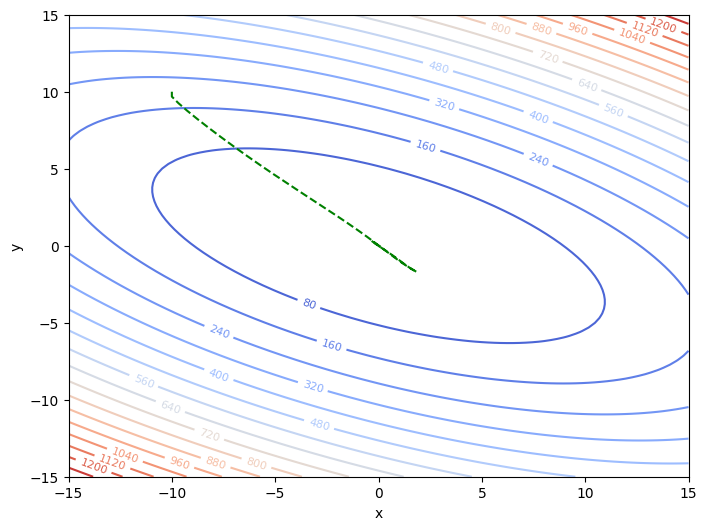

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.74995354  3.49996377]
in 165 iterations


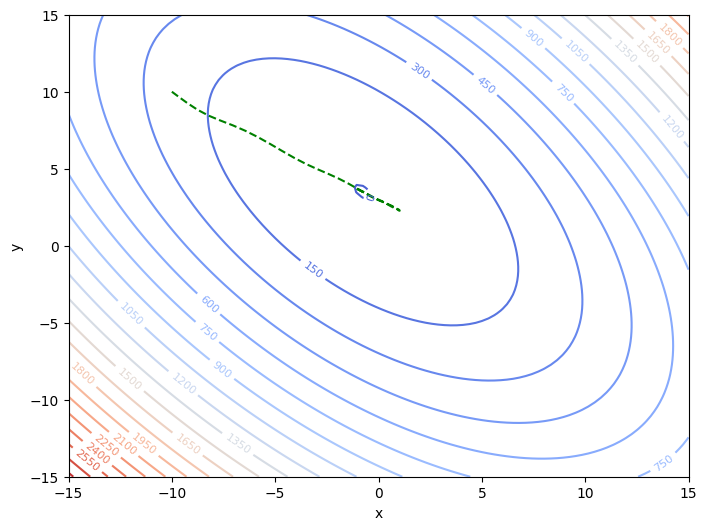

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06722399 -3.89732929]
in 177 iterations


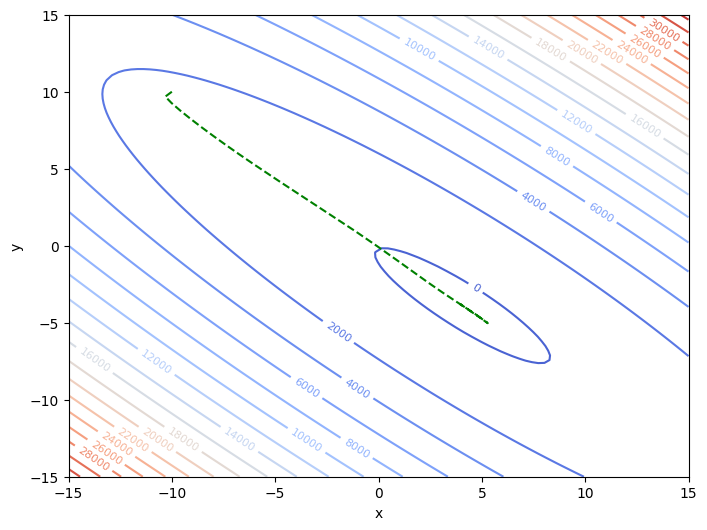

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.2334046  -1.83405775]
in 179 iterations


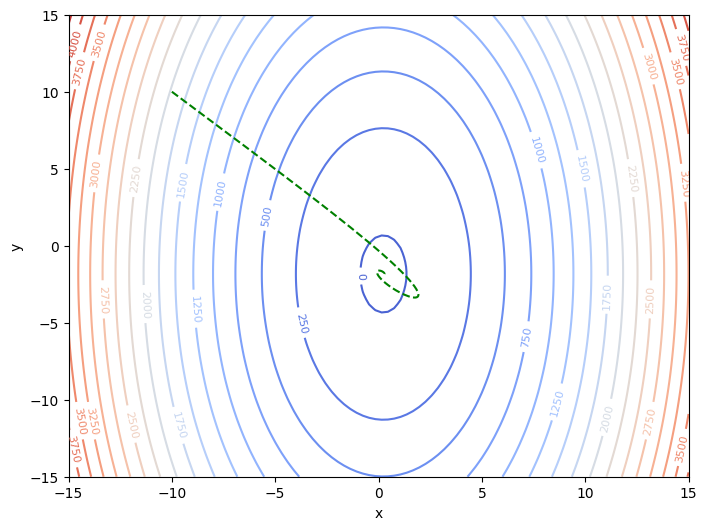

In [15]:
myGD.test_normal()

### Scaled functions

Computing for 1000000x^2 + 2xy + 3y^2:
Found point:  [ 9.19027938e-05 -9.19027943e-05]
in 217 iterations


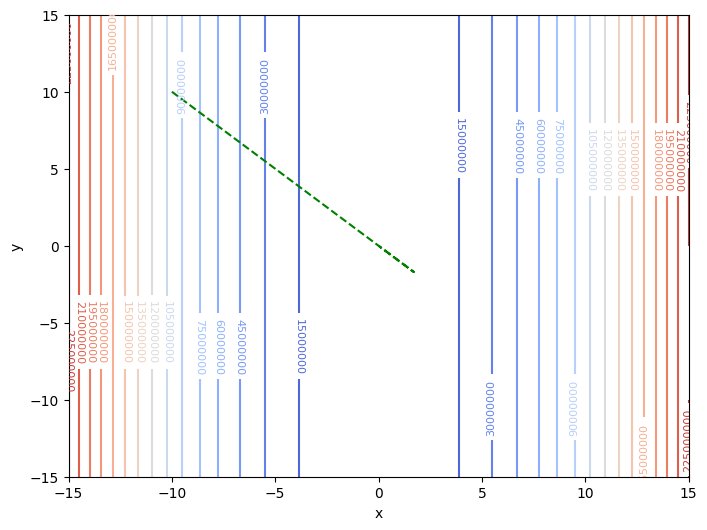

Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [0.99998825 2.33334129]
in 267 iterations


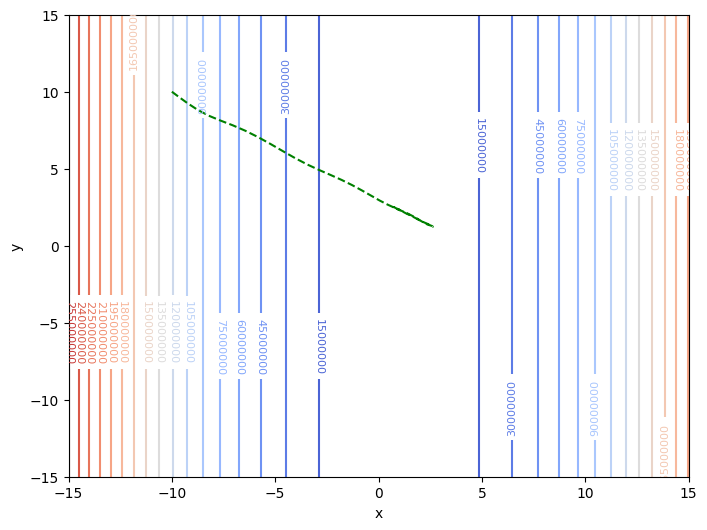

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [ 1.14325574e-01 -3.89255757e-05]
in 276 iterations


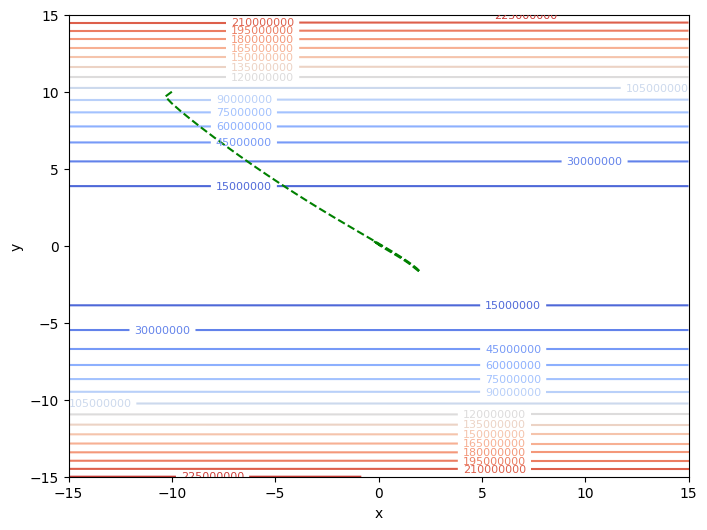

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [ 2.33335576e-01 -4.42866248e-06]
in 277 iterations


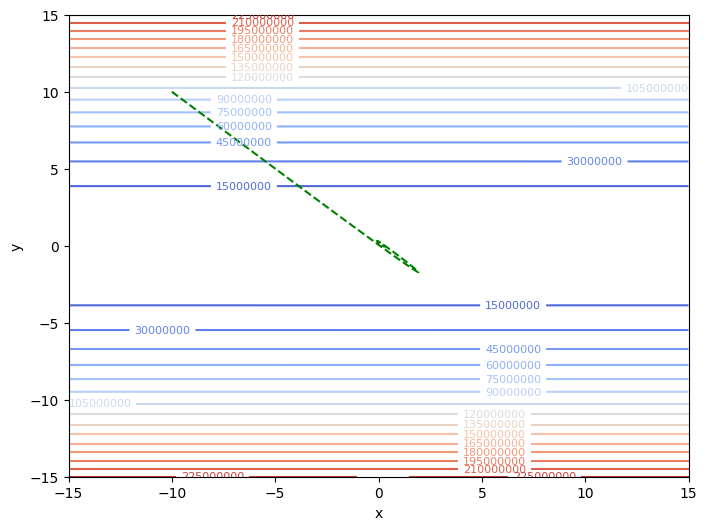

In [16]:
myGD.test_scaling()

### Rosembrock's function

Computing for 100(y - x^2)^2 + (1 - x)^2:
Found point:  [0.42641063 0.18153845]
did not converge


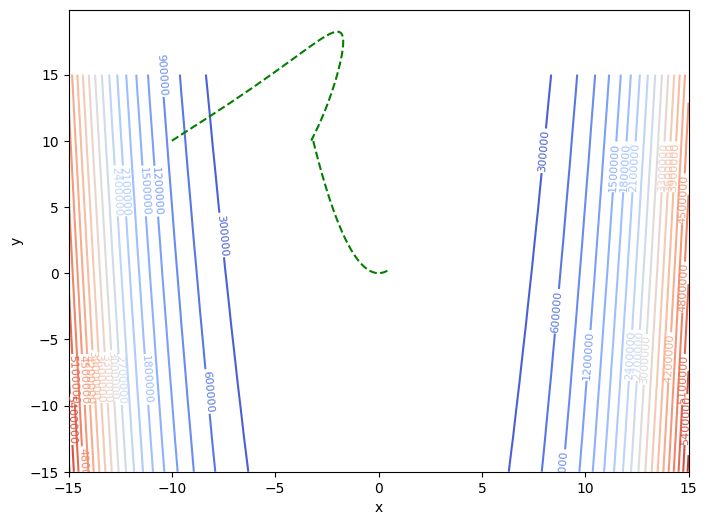

In [17]:
myGD.test_rosembrock()

# Wolfe Conditions

In [18]:
def backtracking(condition):
  alpha = 1000000
  tau = 0.75
  while condition(alpha) == False:
    alpha *= tau
  return alpha

def find_step(function, derivate, xk, direction, epsilon=1e-6):
  difArray = derivate(xk)
  f = lambda alpha : function(xk + alpha * direction)
  c1 = 0.001
  condition = lambda alpha : f(alpha) <= function(xk) + c1 * alpha * (difArray @ np.transpose(direction)) or alpha < epsilon
  return backtracking(condition)

# BFGS

In [19]:
def new_H(s, y, epsilon=0.0000001):
  n = s.shape[0]
  denominator = np.dot(y, s)
  if lin.norm(denominator) < epsilon:
    denominator += epsilon
  rho = 1 / denominator
  B = np.identity(n)
  if rho >= 0:
      B = (np.identity(n) - rho * np.outer(s, y)) @ B @ (np.identity(n) - rho * np.outer(y, s)) + rho * np.outer(s, s)
  return B

def bfgs(fun, der, initial_points, hess=None, epsilon=0.0000001):
  global MAX_ITER
  points = np.array(initial_points)
  last_points = np.array(points)
  n = initial_points.shape[0]
  H = np.identity(n)
  iter = 0
  difArray = der(points)
  last_dif = np.array(difArray)
  sk = np.ones(n)
  while iter <= MAX_ITER and lin.norm(difArray) > epsilon and lin.norm(sk) > epsilon:
    p = np.dot(-H, difArray)
    alpha = find_step(fun, der, points, p, epsilon)
    last_points = np.array(points)
    points = points + alpha * p
    last_dif = np.array(difArray)
    difArray = der(points)

    sk = points - last_points
    yk = difArray - last_dif
    H = new_H(sk, yk)
    iter += 1
  return points, iter, last_points

# def lbfgs(fun, der, initial_points, epsilon=0.0000001):
#   return bfgs(fun, der, initial_points, epsilon, True)



# LBFGS

In [20]:
class MyQueue:
    def __init__(self, m):
        self.m = m  # размер истории
        self.queue = deque()

    def add(self, v: np.array):
        self.queue.append(v)
        if len(self.queue) > self.m:
            self.queue.popleft()

    def get(self):
        return self.queue

    def __getitem__(self, ind: int):
        return self.queue[ind]

    def size(self):
        return len(self.queue)

class LBFGSHistory:
    s = None
    y = None
    rho = None

    def __init__(self, m=3, n=2):
        self.s = MyQueue(m)
        self.y = MyQueue(m)
        self.rho = MyQueue(m)
        a = np.ones(n)
        self.s.add(a)
        self.y.add(a)
        self.rho.add(1.)

    def update(self, x_new, x, g_new, g):
        delta_x = x_new - x
        delta_g = g_new - g
        self.s.add(delta_x)
        self.y.add(delta_g)
        self.rho.add(1. / (np.dot(delta_g, delta_x) + 1e-6))

def calculate_direction(grad, history: LBFGSHistory, h_init):
    q = np.copy(grad)
    m = history.rho.size()
    alpha = np.zeros(m)

    for i in range(m - 1, -1, -1):
        alpha[i] = history.rho[i] * np.dot(history.s[i], q)
        q = q - alpha[i] * history.y[i]

    H_init = np.dot(history.s[-1], history.y[-1]) / (np.dot(history.y[-1], history.y[-1]) + 1e-6)
    r = H_init * q

    for i in range(m):
        beta = history.rho[i] * np.dot(history.y[i], r)
        r = r + history.s[i] * (alpha[i] - beta)

    return -r

In [21]:
def lbfgs(fun, der, initial_points=None, hess=None, epsilon=0.00001, m = 3):

  n = initial_points.shape[0]

  history = LBFGSHistory(m, n)

  point = initial_points[:]
  last_point = point[:]
  k = 0
  difArray = der(point)
  lastDifArray = difArray[:]

  yk = 1
  while (k <= MAX_ITER and lin.norm(difArray) > epsilon):
    p = calculate_direction(difArray, history, h_init=1) 

    alpha = find_step(fun, der, point, p)

    last_point, point = point, point + alpha * p

    lastDifArray, difArray = difArray, der(point)

    history.update(point, last_point, difArray, lastDifArray)

    k += 1
  return point, k, last_point

# Comparison of all methods

In [22]:
def tester(names, functions, derivates, points, minimums, hessians):
  table = np.array(['Function', 'Method', 'found point', 'actual', 'Converged', 'Iterations taken', 'Time taken', 'Used Memory'])
  columns = table.shape[0]
  for method in [myGD.gradient_descent, bfgs, lbfgs]:
    for name, function, derivate, point, minimum, hessian in zip(names, functions, derivates, points, minimums, hessians):
      start_time = time.time()
      process = psutil.Process(os.getpid())
      tracemalloc.start()
      result = method(function, derivate, point, hess=hessian)
      total_mem = tracemalloc.get_traced_memory()[1]
      tracemalloc.stop()
      total_time = round(time.time() - start_time, 4)
      table = np.append(table, np.array([name,
                                            method.__name__,                                        
                                            result[2], minimum, result[1] <= GD.MAX_ITERATIONS,
                                            result[1], str(total_time) + ' s', str(total_mem) + ' bytes'], dtype=object))
  
  table = np.reshape(table, ((int)(table.size / columns), columns))
  print(tabulate(table, headers='firstrow', tablefmt='fancy_grid'))

print("==========================Normal Testing========================")
tester(names, functions, derivates, default_points, minimums, hessian)
print()
print()

print("==========================Scaled Testing========================")
tester(names_with_scaling, functions_with_scaling, derivates_with_scaling, default_points, mimimums_with_scaling, hessian_with_scaling)
print()
print()

print("==========================Rosembrock Test========================")
tester(name_ros, function_ros, derivate_ros, default_points, minimum_ros, hessian_ros)
print()
print()

==========================Normal Testing========================
╒══════════════════════════════════════╤══════════════════╤═══════════════════════════════════╤═════════════════╤═════════════╤════════════════════╤══════════════╤═══════════════╕
│ Function                             │ Method           │ found point                       │ actual          │ Converged   │   Iterations taken │ Time taken   │ Used Memory   │
╞══════════════════════════════════════╪══════════════════╪═══════════════════════════════════╪═════════════════╪═════════════╪════════════════════╪══════════════╪═══════════════╡
│ x^2 + 2xy + 3y^2                     │ gradient_descent │ [ 0.00020844 -0.00021121]         │ [0 0]           │ True        │                175 │ 0.0579 s     │ 11881 bytes   │
├──────────────────────────────────────┼──────────────────┼───────────────────────────────────┼─────────────────┼─────────────┼────────────────────┼──────────────┼───────────────┤
│ 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3